In [1]:

# ============================================================
# CELDA 1. CARGA DE DATOS PARA EL EDA DE AEROPUERTOS
# Y AEROLÍNEAS
# ============================================================

# Importamos las librerías que utilizaremos para trabajar
# con la muestra y generar nuestras dos visualizaciones.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
from IPython.display import display

# Conectamos Google Drive para recuperar la misma muestra
# que utilizó el primer integrante en su análisis.
drive.mount("/content/drive")

# Definimos la ruta del Parquet de 120,000 vuelos.
# Este archivo ya fue generado en el EDA anterior.
RUTA_DATOS = Path(
    "/content/drive/MyDrive/flight_delay_bigdata/"
    "sample/muestra_historica_bts.parquet"
)

# Verificamos que exista antes de intentar leerlo.
if not RUTA_DATOS.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {RUTA_DATOS}"
    )

# Leemos el Parquet sin descargar nuevamente los ZIP.
df = pd.read_parquet(RUTA_DATOS)

# Estandarizamos los nombres de las columnas.
df.columns = df.columns.str.strip().str.upper()

# Comprobamos las variables necesarias para este EDA.
# ORIGIN identifica el aeropuerto de origen.
# REPORTING_AIRLINE identifica la aerolínea.
# DEPDELAY indica los minutos de retraso de salida.
columnas = [
    "ORIGIN",
    "REPORTING_AIRLINE",
    "DEPDELAY",
    "CANCELLED"
]

faltantes = [
    columna for columna in columnas
    if columna not in df.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias: {faltantes}"
    )

# Trabajamos en una copia para conservar el dataset.
eda = df.copy()

# Convertimos los retrasos y cancelaciones a números.
eda["DEPDELAY"] = pd.to_numeric(
    eda["DEPDELAY"], errors="coerce"
)

eda["CANCELLED"] = pd.to_numeric(
    eda["CANCELLED"], errors="coerce"
)

# Para calcular la puntualidad excluimos vuelos cancelados.
# La cancelación es un resultado diferente del retraso.
eda = eda[eda["CANCELLED"] == 0].copy()

# Eliminamos filas sin aeropuerto, aerolínea o retraso.
eda = eda.dropna(
    subset=["ORIGIN", "REPORTING_AIRLINE", "DEPDELAY"]
).copy()

# Definimos retraso como salida 15 minutos o más tarde.
eda["delayed_15"] = (
    eda["DEPDELAY"] >= 15
).astype(int)

# Revisamos que la muestra se haya cargado correctamente.
print("Vuelos originales:", f"{len(df):,}")
print("Vuelos válidos para el EDA:", f"{len(eda):,}")
print("Aeropuertos de origen:", eda["ORIGIN"].nunique())
print("Aerolíneas:", eda["REPORTING_AIRLINE"].nunique())
print(
    "Tasa general de retrasos:",
    f"{eda['delayed_15'].mean() * 100:.2f}%"
)

display(
    eda[
        ["ORIGIN", "REPORTING_AIRLINE", "DEPDELAY", "delayed_15"]
    ].head()
)


Mounted at /content/drive
Vuelos originales: 120,000
Vuelos válidos para el EDA: 118,255
Aeropuertos de origen: 355
Aerolíneas: 15
Tasa general de retrasos: 21.06%


,ORIGIN,REPORTING_AIRLINE,DEPDELAY,delayed_15
0,SRQ,G4,-20.0,0
1,BNA,WN,-7.0,0
2,DFW,AA,-4.0,0
3,RSW,UA,-4.0,0
4,ATL,DL,-2.0,0


Retrasos de salida en los 15 aeropuertos más frecuentes:


,ORIGIN,total_vuelos,vuelos_retrasados,tasa_retraso_pct
5,DFW,5113,1458,28.52
2,CLT,3545,900,25.39
4,DEN,5364,1358,25.32
10,MCO,2846,672,23.61
11,ORD,5102,1189,23.30
3,DCA,2299,525,22.84
7,LAS,3143,712,22.65
14,SFO,2339,503,21.50
0,ATL,5542,1179,21.27
12,PHX,3387,712,21.02


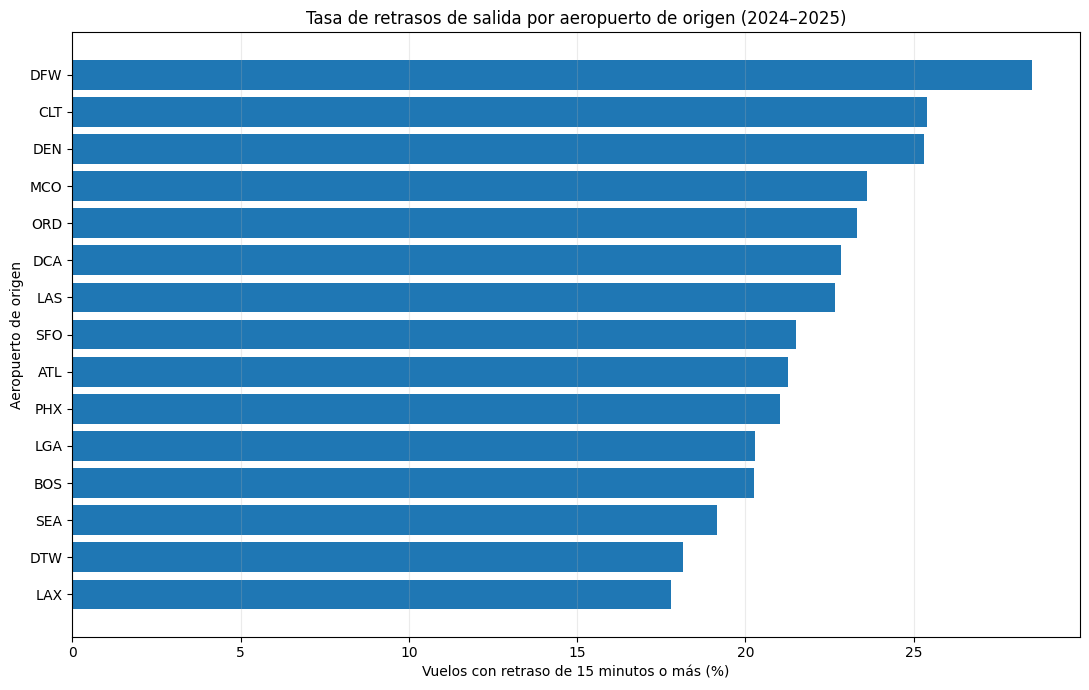

Mayor tasa entre los 15 aeropuertos: DFW (28.52%)
Vuelos analizados en ese aeropuerto: 5,113


In [2]:

# ============================================================
# CELDA 2. ANÁLISIS DE RETRASOS POR AEROPUERTO DE ORIGEN
# ============================================================

# Primero contamos cuántos vuelos salieron de cada aeropuerto.
# Seleccionamos los 15 aeropuertos con mayor cantidad de
# registros dentro de nuestra muestra de BTS.

top_aeropuertos = (
    eda["ORIGIN"]
    .value_counts()
    .head(15)
    .index
)

# Filtramos los vuelos de esos 15 aeropuertos.
eda_aeropuertos = eda[
    eda["ORIGIN"].isin(top_aeropuertos)
].copy()

# Calculamos el total de vuelos, los retrasos registrados
# y la tasa de retrasos por aeropuerto de origen.
retrasos_aeropuerto = (
    eda_aeropuertos
    .groupby("ORIGIN")
    .agg(
        total_vuelos=("delayed_15", "size"),
        vuelos_retrasados=("delayed_15", "sum"),
        tasa_retraso=("delayed_15", "mean")
    )
    .reset_index()
)

# Convertimos la tasa de retraso a porcentaje.
retrasos_aeropuerto["tasa_retraso_pct"] = (
    retrasos_aeropuerto["tasa_retraso"] * 100
)

# Ordenamos de mayor a menor porcentaje de retrasos.
retrasos_aeropuerto = retrasos_aeropuerto.sort_values(
    "tasa_retraso_pct",
    ascending=False
)

# Mostramos la tabla de resultados.
print("Retrasos de salida en los 15 aeropuertos más frecuentes:")

display(
    retrasos_aeropuerto[
        [
            "ORIGIN",
            "total_vuelos",
            "vuelos_retrasados",
            "tasa_retraso_pct"
        ]
    ].round(2)
)

# Creamos una gráfica de barras horizontales.
# Las barras representan el porcentaje de vuelos retrasados,
# no la cantidad total de vuelos.
plt.figure(figsize=(11, 7))

plt.barh(
    retrasos_aeropuerto["ORIGIN"],
    retrasos_aeropuerto["tasa_retraso_pct"]
)

# Colocamos arriba el aeropuerto con mayor tasa.
plt.gca().invert_yaxis()

plt.title(
    "Tasa de retrasos de salida por aeropuerto de origen (2024–2025)"
)
plt.xlabel("Vuelos con retraso de 15 minutos o más (%)")
plt.ylabel("Aeropuerto de origen")
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Mostramos el aeropuerto con mayor tasa de retrasos.
aeropuerto_mayor = retrasos_aeropuerto.iloc[0]

print(
    f"Mayor tasa entre los 15 aeropuertos: "
    f"{aeropuerto_mayor['ORIGIN']} "
    f"({aeropuerto_mayor['tasa_retraso_pct']:.2f}%)"
)

print(
    f"Vuelos analizados en ese aeropuerto: "
    f"{int(aeropuerto_mayor['total_vuelos']):,}"
)


### Interpretación: retrasos por aeropuerto de origen

Al comparar los 15 aeropuertos con mayor número de vuelos en nuestra muestra de 2024 y 2025, encontramos que DFW (Dallas/Fort Worth) presentó la mayor tasa de retrasos, con un 28.52% de sus 5,113 vuelos analizados. También destacan CLT (Charlotte) y DEN (Denver), ambos con porcentajes superiores al 25%. Por otro lado, LAX (Los Ángeles) presentó la tasa más baja entre los aeropuertos seleccionados, con aproximadamente 17.79%.

Estos resultados muestran que el aeropuerto de origen puede influir en la probabilidad de que un vuelo salga retrasado. Por eso, consideramos importante incluir esta variable en nuestros modelos predictivos, aunque también debemos analizar otros factores como el clima, la aerolínea y los horarios de salida.

Comparación de retrasos por aerolínea:


,REPORTING_AIRLINE,total_vuelos,vuelos_retrasados,tasa_retraso_pct
5,F9,3420,970,28.36
3,B6,3995,1022,25.58
1,AA,16451,4101,24.93
13,WN,23560,5553,23.57
10,OH,3874,908,23.44
9,NK,3720,852,22.90
6,G4,2082,452,21.71
2,AS,4116,821,19.95
12,UA,13235,2550,19.27
8,MQ,4939,949,19.21


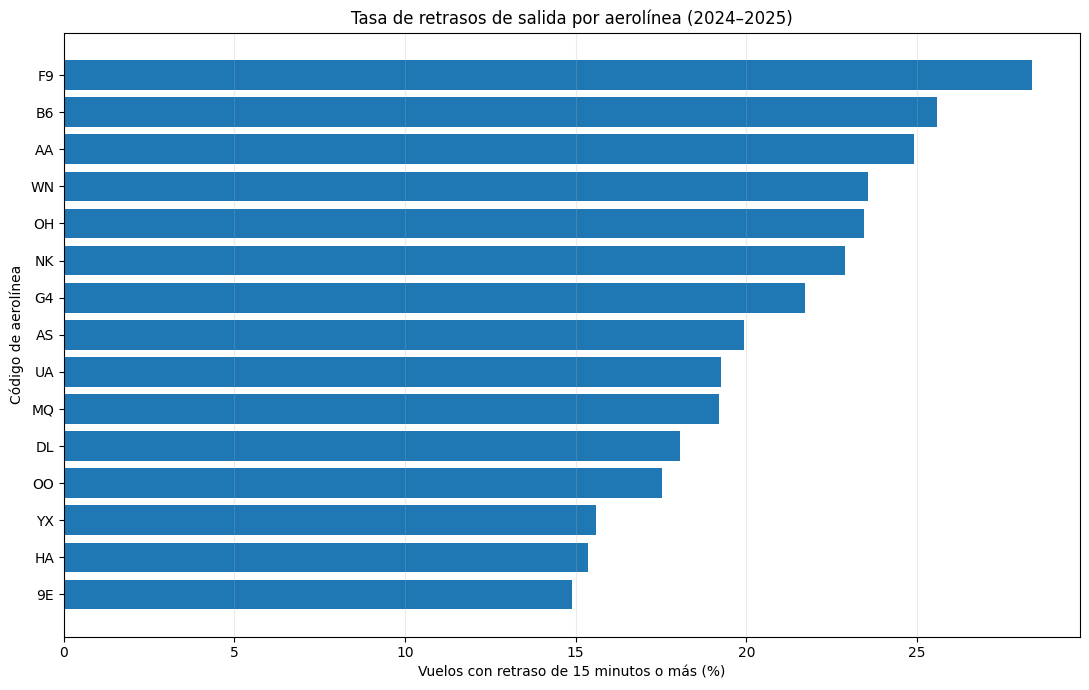

Mayor tasa de retrasos: F9 (28.36%)
Menor tasa de retrasos: 9E (14.90%)


In [3]:

# ============================================================
# CELDA 3. ANÁLISIS DE RETRASOS POR AEROLÍNEA
# ============================================================

# Agrupamos los vuelos por aerolínea y calculamos:
# - Total de vuelos analizados
# - Cantidad de vuelos retrasados
# - Porcentaje de vuelos retrasados

retrasos_aerolinea = (
    eda
    .groupby("REPORTING_AIRLINE")
    .agg(
        total_vuelos=("delayed_15", "size"),
        vuelos_retrasados=("delayed_15", "sum"),
        tasa_retraso=("delayed_15", "mean")
    )
    .reset_index()
)

# Convertimos la tasa de retrasos a porcentaje.
retrasos_aerolinea["tasa_retraso_pct"] = (
    retrasos_aerolinea["tasa_retraso"] * 100
)

# Establecemos un mínimo de 100 vuelos por aerolínea
# para evitar comparaciones basadas en pocos registros.
MIN_VUELOS = 100

retrasos_aerolinea = retrasos_aerolinea[
    retrasos_aerolinea["total_vuelos"] >= MIN_VUELOS
].copy()

# Ordenamos de mayor a menor tasa de retrasos.
retrasos_aerolinea = retrasos_aerolinea.sort_values(
    "tasa_retraso_pct",
    ascending=False
)

# Mostramos los resultados en una tabla.
print("Comparación de retrasos por aerolínea:")

display(
    retrasos_aerolinea[
        [
            "REPORTING_AIRLINE",
            "total_vuelos",
            "vuelos_retrasados",
            "tasa_retraso_pct"
        ]
    ].round(2)
)

# Generamos una gráfica de barras horizontales.
plt.figure(figsize=(11, 7))

plt.barh(
    retrasos_aerolinea["REPORTING_AIRLINE"],
    retrasos_aerolinea["tasa_retraso_pct"]
)

# Mostramos primero las aerolíneas con mayor tasa.
plt.gca().invert_yaxis()

plt.title(
    "Tasa de retrasos de salida por aerolínea (2024–2025)"
)
plt.xlabel("Vuelos con retraso de 15 minutos o más (%)")
plt.ylabel("Código de aerolínea")

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Identificamos las aerolíneas con mayor y menor
# porcentaje de retrasos dentro de nuestra muestra.
if not retrasos_aerolinea.empty:

    mayor = retrasos_aerolinea.iloc[0]
    menor = retrasos_aerolinea.iloc[-1]

    print(
        f"Mayor tasa de retrasos: "
        f"{mayor['REPORTING_AIRLINE']} "
        f"({mayor['tasa_retraso_pct']:.2f}%)"
    )

    print(
        f"Menor tasa de retrasos: "
        f"{menor['REPORTING_AIRLINE']} "
        f"({menor['tasa_retraso_pct']:.2f}%)"
    )

else:
    print("No hay aerolíneas que cumplan el mínimo de vuelos.")


### Interpretación: retrasos por aerolínea

En la comparación entre aerolíneas, encontramos que F9 (Frontier Airlines) presentó el mayor porcentaje de vuelos retrasados, con un 28.36%, seguida de B6 (JetBlue) y AA (American Airlines). En cambio, 9E (Endeavor Air) registró uno de los porcentajes más bajos, cercano al 15%.

La diferencia entre aerolíneas sugiere que la compañía que opera el vuelo también podría ser una variable relevante para predecir retrasos. Sin embargo, estos resultados no significan necesariamente que una aerolínea sea menos eficiente que otra, ya que las rutas, los aeropuertos y los horarios pueden afectar sus resultados.

### Conclusión del análisis exploratorio

En este análisis identificamos diferencias importantes en los retrasos dependiendo del aeropuerto de origen y de la aerolínea. DFW y Frontier Airlines presentaron las tasas más altas dentro de los grupos analizados, lo que nos indica que ambas características podrían ayudar a explicar los retrasos de salida. Estos hallazgos servirán como punto de partida para seleccionar variables en los modelos de Machine Learning, aunque será necesario comprobar su importancia durante el entrenamiento.
